1. Set your own seed

In [ ]:
# ⚠️ REPLACE THIS with your own roll number, e.g. 22 for roll no. AP22110010022
ROLL_NUMBER = 67

print(f"Using random seed = {ROLL_NUMBER}")

Using random seed = 67


2.Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid') if 'seaborn-v0_8-whitegrid' in plt.style.available else None

3.Load and explore the iris dataset

In [ ]:
iris = load_iris()

X = iris.data                     # features: sepal/petal length & width
y = iris.target                   # target: 0 = setosa, 1 = versicolor, 2 = virginica
feature_names = iris.feature_names
target_names = iris.target_names

df = pd.DataFrame(X, columns=feature_names)
df['species'] = [target_names[i] for i in y]

print("Shape of dataset:", df.shape)
print("\nClass distribution:")
print(df['species'].value_counts())

df.head(10)

Shape of dataset: (150, 5)

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


4.Train test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=ROLL_NUMBER, stratify=y
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples : {X_test.shape[0]}")

Training samples: 105
Testing samples : 45


5.Worked example

In [ ]:
# Take the first test flower
sample = X_test[0]
true_label = target_names[y_test[0]]

# Compute Euclidean distance from this sample to every training point
distances = np.sqrt(np.sum((X_train - sample) ** 2, axis=1))

# Find indices of the 5 nearest neighbours
k = 5
nearest_idx = np.argsort(distances)[:k]
nearest_labels = [target_names[y_train[i]] for i in nearest_idx]

print("Test flower measurements:", dict(zip(feature_names, sample.round(2))))
print("True species:", true_label)
print(f"\n{k} nearest neighbours' species:", nearest_labels)

# Majority vote
from collections import Counter
vote = Counter(nearest_labels).most_common(1)[0][0]
print(f"\nMajority vote prediction: {vote}")
print("Correct!" if vote == true_label else "Incorrect!")

Test flower measurements: {'sepal length (cm)': np.float64(6.7), 'sepal width (cm)': np.float64(3.1), 'petal length (cm)': np.float64(4.7), 'petal width (cm)': np.float64(1.5)}
True species: versicolor

5 nearest neighbours' species: [np.str_('versicolor'), np.str_('versicolor'), np.str_('versicolor'), np.str_('versicolor'), np.str_('versicolor')]

Majority vote prediction: versicolor
Correct!


6.Building the KNN classifier with scikit learn

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Predictions generated for", len(y_pred), "test samples.")

Predictions generated for 45 test samples.


7.Printing correct and wrong predictions

In [ ]:
results = pd.DataFrame(X_test, columns=feature_names)
results['Actual']    = [target_names[i] for i in y_test]
results['Predicted'] = [target_names[i] for i in y_pred]
results['Result']    = np.where(results['Actual'] == results['Predicted'], 'Correct', 'Wrong')

correct = results[results['Result'] == 'Correct'].reset_index(drop=True)
wrong   = results[results['Result'] == 'Wrong'].reset_index(drop=True)

print("=" * 70)
print(f"CORRECT PREDICTIONS ({len(correct)} out of {len(results)})")
print("=" * 70)
print(correct.to_string(index=True))

print("\n" + "=" * 70)
print(f"WRONG PREDICTIONS ({len(wrong)} out of {len(results)})")
print("=" * 70)
if len(wrong) > 0:
    print(wrong.to_string(index=True))
else:
    print("None — every test sample was classified correctly for this split/seed.")

CORRECT PREDICTIONS (42 out of 45)
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)      Actual   Predicted   Result
0                 6.7               3.1                4.7               1.5  versicolor  versicolor  Correct
1                 7.9               3.8                6.4               2.0   virginica   virginica  Correct
2                 5.6               3.0                4.5               1.5  versicolor  versicolor  Correct
3                 5.1               3.4                1.5               0.2      setosa      setosa  Correct
4                 5.4               3.4                1.5               0.4      setosa      setosa  Correct
5                 7.7               2.6                6.9               2.3   virginica   virginica  Correct
6                 5.6               2.5                3.9               1.1  versicolor  versicolor  Correct
7                 5.0               3.0                1.6               0.2      set

8.Model evaluation

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}  ({accuracy*100:.2f}%)\n")

print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=[f"Actual {n}" for n in target_names],
                          columns=[f"Pred {n}" for n in target_names])
print(cm_df)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

Accuracy: 0.9333  (93.33%)

Confusion Matrix:
                   Pred setosa  Pred versicolor  Pred virginica
Actual setosa               15                0               0
Actual versicolor            0               14               1
Actual virginica             0                2              13

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



9.How does accuracy change with  k

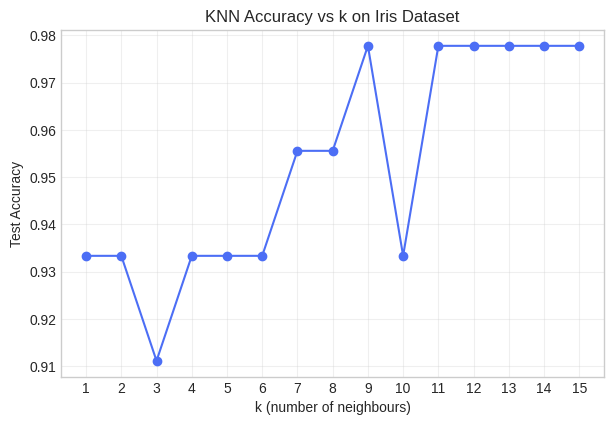

Best k for this split: 9  (Accuracy: 0.9778)


In [ ]:
k_values = range(1, 16)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    accuracies.append(acc)

plt.figure(figsize=(7, 4.5))
plt.plot(list(k_values), accuracies, marker='o', color='#4C6EF5')
plt.xlabel('k (number of neighbours)')
plt.ylabel('Test Accuracy')
plt.title('KNN Accuracy vs k on Iris Dataset')
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

best_k = list(k_values)[int(np.argmax(accuracies))]
print(f"Best k for this split: {best_k}  (Accuracy: {max(accuracies):.4f})")

2. Try k = 1, k = 3, and k = 9. How does the number of wrong predictions change?

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Different K value
k_values = [1]

for k in k_values:

    # Create KNN model
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')

    # Train the model
    knn.fit(X_train, y_train)

    # Make predictions
    y_pred = knn.predict(X_test)

    # Count wrong predictions
    wrong_predictions = sum(y_pred != y_test)

    # Count correct predictions
    correct_predictions = sum(y_pred == y_test)

    print("K =", k)
    print("Correct Predictions =", correct_predictions)
    print("Wrong Predictions =", wrong_predictions)
    print()

K = 1
Correct Predictions = 42
Wrong Predictions = 3



In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Different K value
k_values = [3]

for k in k_values:

    # Create KNN model
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')


    knn.fit(X_train, y_train)

    # Make predictions
    y_pred = knn.predict(X_test)

    # Count wrong predictions
    wrong_predictions = sum(y_pred != y_test)

    # Count correct predictions
    correct_predictions = sum(y_pred == y_test)

    print("K =", k)
    print("Correct Predictions =", correct_predictions)
    print("Wrong Predictions =", wrong_predictions)
    print()

K = 3
Correct Predictions = 41
Wrong Predictions = 4



In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Different K value
k_values = [9]

for k in k_values:

    # Create KNN model
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')

    knn.fit(X_train, y_train)

    # Make predictions
    y_pred = knn.predict(X_test)

    # Count wrong predictions
    wrong_predictions = sum(y_pred != y_test)


    correct_predictions = sum(y_pred == y_test)

    print("K =", k)
    print("Correct Predictions =", correct_predictions)
    print("Wrong Predictions =", wrong_predictions)
    print()

K = 9
Correct Predictions = 44
Wrong Predictions = 1



3. Change the `metric` parameter of `KNeighborsClassifier` from `'euclidean'` to `'manhattan'`. Does accuracy change?

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Euclidean Distance
knn_euclidean = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn_euclidean.fit(X_train, y_train)
y_pred_euclidean = knn_euclidean.predict(X_test)

accuracy_euclidean = accuracy_score(y_test, y_pred_euclidean)

print("Euclidean Distance Accuracy:", accuracy_euclidean * 100)


# Manhattan Distance
knn_manhattan = KNeighborsClassifier(n_neighbors=5, metric='manhattan')
knn_manhattan.fit(X_train, y_train)
y_pred_manhattan = knn_manhattan.predict(X_test)

accuracy_manhattan = accuracy_score(y_test, y_pred_manhattan)

print("Manhattan Distance Accuracy:", accuracy_manhattan * 100)

Euclidean Distance Accuracy: 93.33333333333333
Manhattan Distance Accuracy: 93.33333333333333


4. In Section 10, look at your **wrong predictions** (if any). Which two species are most often confused with each other, and why do you think that happens (hint: look at the confusion matrix)?

In [ ]:
# Use the confusion matrix created in Section 11
confusion_counts = cm.copy()

# Remove correct predictions (diagonal values)
np.fill_diagonal(confusion_counts, 0)

# Find the largest wrong prediction
max_index = np.unravel_index(np.argmax(confusion_counts), confusion_counts.shape)

actual_species = target_names[max_index[0]]
predicted_species = target_names[max_index[1]]
number_confused = confusion_counts[max_index]

print("Most common confusion:")
print("Actual species:", actual_species)
print("Predicted as:", predicted_species)
print("Number of confused predictions:", number_confused)

print("\nWrong predictions:")
if len(wrong) > 0:
    print(wrong[['Actual', 'Predicted']])
else:
    print("There are no wrong predictions for this train-test split.")

Most common confusion:
Actual species: virginica
Predicted as: versicolor
Number of confused predictions: 2

Wrong predictions:
       Actual   Predicted
0  versicolor   virginica
1   virginica  versicolor
2   virginica  versicolor
